# 02: Fenotipificación de Resiliencia Motora (Sprint 2 / DEC-020)

**Proyecto:** MAIA - Fundación Canguro  
**Fase:** Sprint 2 (Ticket 2.2)  
**Decisiones Metodológicas Relacionadas:** [DEC-010](file:///docs/decisiones.md), [DEC-011](file:///docs/decisiones.md), [DEC-018](file:///docs/decisiones.md), [DEC-020](file:///docs/decisiones.md)

---

### Contexto Metodológico y Justificación de DEC-020
La resiliencia motora se conceptualiza como un **desempeño motor (Software, $SW$) superior al esperado dado el sustrato neural subcortical (Hardware, $HW$)**. 

En la revisión técnica del modelo del target (PR #25) se adoptaron dos decisiones fundamentales registradas en **DEC-020**:

1. **Target Principal Univariado sin Covariables Clínicas ($SW_{motor} \sim hw\_motor\_qc$):**
   - La propuesta inicial incluía sexo (`BIRTH_sexo5`) y fragilidad (`FOLLOW_Fragility_Rasch_441_2PL`) en la regresión del target.
   - Sin embargo, al incluirlos en la regresión, el residual queda por construcción ortogonal a ellos ($r = 0.000$ con fragilidad).
   - El **Objetivo 4 de la propuesta** y el **Ticket 3.2** buscan precisamente evaluar qué variables perinatales y clínicas predicen la resiliencia. Incluir sexo y fragilidad en el target anularía su capacidad predictiva en los modelos de Sprint 3.
   - Por tanto, el target principal es **univariado**, reservando sexo y fragilidad como predictores en Sprint 3 (DEC-007). Se exporta la versión multivariada como sensibilidad (`resilience_score_adj`).

2. **Regresión Robusta (`HuberRegressor`) como Modelo Primario:**
   - La distribución del desempeño motor $SW_{motor}$ exhibe asimetría negativa fuerte ($\approx -2.63$) debido a unos pocos sujetos con tiempos extremadamente lentos en el Nine-Hole Peg Test (NHPT), con un mínimo de $SW_{motor} = -11.63$.
   - En OLS, estos casos atípicos arrastran fuertemente la recta ($b_{OLS} = 0.54$, con 6 observaciones con distancia de Cook $> 4/n$).
   - En consonancia con DEC-010 y DEC-018 (donde se seleccionó estandarización robusta por la misma razón), se adopta **HuberRegressor** ($b_{Huber} = 0.31$, intercepto = $-0.10$), dejando OLS como sensibilidad.

3. **Criterios de Binarización:**
   - **Corte Conceptual en 0.0 (`is_resilient`):** Residual $> 0.0$ ("rinde mejor de lo esperado dado su cerebro"). Resulta en $53.6\%$ resilientes ($N=90/168$).
   - **Corte Empírico en Mediana (`is_resilient_median`):** Residual $>$ mediana ($+0.14$), garantizando balance exacto $50.0\%$ ($N=84/168$) para modelos de clasificación de Sprint 3.

In [1]:
import sys
from pathlib import Path

# Asegurar acceso a los módulos de src/
PROJECT_ROOT = Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import kurtosis, skew
from sklearn.linear_model import LinearRegression
from sklearn.metrics import cohen_kappa_score

# Configuración estética para visualización científica
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update(
    {
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "figure.titlesize": 13,
        "figure.dpi": 110,
    }
)

print("Entorno configurado correctamente.")

Entorno configurado correctamente.


## 1. Carga de Datos y Consolidación de Cohortes ECA

Cargamos el hardware motor preprocesado (`hw_motor.parquet`) y las cohortes del Ensayo Controlado Aleatorizado (Canguro y Tradicional) desde `data/interim/`, aplicando el pipeline modular oficial `src.features.build_target`.

In [2]:
from src.features.build_target import (
    compute_sw_motor,
    fit_resilience_model,
    load_sources,
    merge_and_filter_cohort,
)

# 1. Cargar fuentes reales
hw_df, eca_df = load_sources()
print(f"Hardware motor cargado: {hw_df.shape[0]} registros.")
print(f"Cohortes ECA combinadas: {eca_df.shape[0]} registros.")

# 2. Merge y filtrado de la muestra analítica (fit_sample: Canguro + Tradicional)
df_analytical = merge_and_filter_cohort(hw_df, eca_df)
print(
    f"Muestra analítica consolidada (fit_sample): {len(df_analytical)} participantes."
)
assert len(df_analytical) == 209, (
    f"Esperado 209 participantes en fit_sample, obtenido {len(df_analytical)}"
)

# 3. Cálculo de Software Motor robusto (SW_motor)
df_analytical["SW_motor"] = compute_sw_motor(df_analytical)
print(
    f"SW_motor calculado: media={df_analytical['SW_motor'].mean():.3f}, "
    f"mediana={df_analytical['SW_motor'].median():.3f}, "
    f"mín={df_analytical['SW_motor'].min():.3f}, "
    f"máx={df_analytical['SW_motor'].max():.3f}"
)

Hardware motor cargado: 299 registros.
Cohortes ECA combinadas: 441 registros.
Muestra analítica consolidada (fit_sample): 209 participantes.
SW_motor calculado: media=-0.452, mediana=0.000, mín=-11.635, máx=2.698


## 2. Ajuste de Modelos: HuberRegressor (Principal) vs. OLS (Sensibilidad)

Comparamos el ajuste univariado $SW_{motor} \sim hw\_motor\_qc$ mediante:
1. **HuberRegressor:** Estimador M robusto a valores atípicos mediante función de pérdida Huber.
2. **LinearRegression (OLS):** Mínimos cuadrados ordinarios susceptibles al apalancamiento de atípicos extremos.

In [3]:
# Ajustar modelo principal de Huber y sensibilidades
modeled_df, huber_model, r2_ols = fit_resilience_model(df_analytical)
print(f"Muestra final con QC y covariables completas: {len(modeled_df)} participantes.")
assert len(modeled_df) == 168, (
    f"Esperado 168 participantes modelados, obtenido {len(modeled_df)}"
)

X = modeled_df[["hw_motor_qc"]]
y = modeled_df["SW_motor"]

huber_slope = float(huber_model.coef_[0])
huber_intercept = float(huber_model.intercept_)
huber_residuals = modeled_df["resilience_score"]

ols_residuals = modeled_df["resilience_score_ols"]
ols_univ = LinearRegression().fit(X, y)
ols_univ_slope = float(ols_univ.coef_[0])
ols_univ_intercept = float(ols_univ.intercept_)

print("=== COMPARACIÓN DE MODELOS UNIVARIADOS (SW_motor ~ hw_motor_qc) ===")
print(f"Huber: Pendiente (b) = {huber_slope:.4f} | Intercepto = {huber_intercept:.4f}")
print(
    f"OLS:   Pendiente (b) = {ols_univ_slope:.4f} | Intercepto = {ols_univ_intercept:.4f}"
)
print(f"R² OLS univariado: {r2_ols:.4f}")

Muestra final con QC y covariables completas: 168 participantes.
=== COMPARACIÓN DE MODELOS UNIVARIADOS (SW_motor ~ hw_motor_qc) ===
Huber: Pendiente (b) = 0.3113 | Intercepto = -0.1019
OLS:   Pendiente (b) = 0.5435 | Intercepto = -0.3736
R² OLS univariado: 0.0222


## 3. Diagnóstico de Influencia y Casos Atípicos (Distancia de Cook)

Evaluamos la presencia de observaciones influyentes en OLS que distorsionan la pendiente de la recta, justificando empíricamente la adopción de `HuberRegressor` (DEC-020).

In [4]:
# Cálculo de Leverage (H) y Distancia de Cook en OLS
X_mat = np.column_stack([np.ones(len(X)), X["hw_motor_qc"].values])
H = X_mat @ np.linalg.inv(X_mat.T @ X_mat) @ X_mat.T
h_ii = np.diag(H)

mse_ols = np.mean(ols_residuals**2)
p_params = 2
cooks_d = (ols_residuals**2 / (p_params * mse_ols)) * (h_ii / (1 - h_ii) ** 2)

threshold_cook = 4 / len(modeled_df)
n_influential = int(np.sum(cooks_d > threshold_cook))

scale = float(huber_model.scale_)
delta = 1.35 * scale
abs_r = np.abs(huber_residuals)
huber_weights = np.where(abs_r <= delta, 1.0, delta / abs_r)
n_downweighted = int(np.sum(huber_weights < 1.0))

print(f"Umbral de Distancia de Cook (4/n): {threshold_cook:.4f}")
print(f"Observaciones con Cook's D > 4/n: {n_influential}")
print(f"Observaciones ponderadas a la baja por Huber: {n_downweighted}")

# Identificar el caso más influyente/extremo
min_pos = int(np.argmin(y.to_numpy()))
print(
    f"Participante con menor SW_motor: Código {modeled_df.iloc[min_pos]['code']}, "
    f"SW_motor = {y.iloc[min_pos]:.2f}, hw_motor_qc = {X.iloc[min_pos]['hw_motor_qc']:.2f}, "
    f"Cook's D = {cooks_d[min_pos]:.4f}, Peso Huber = {huber_weights[min_pos]:.4f}"
)

Umbral de Distancia de Cook (4/n): 0.0238
Observaciones con Cook's D > 4/n: 6
Observaciones ponderadas a la baja por Huber: 57
Participante con menor SW_motor: Código 426, SW_motor = -11.63, hw_motor_qc = -0.84, Cook's D = 0.6475, Peso Huber = 0.0884


C:\Users\mhgua\Documents\Andes\202621\Proyecto\ProyectoFinal-FundacionCanguro\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


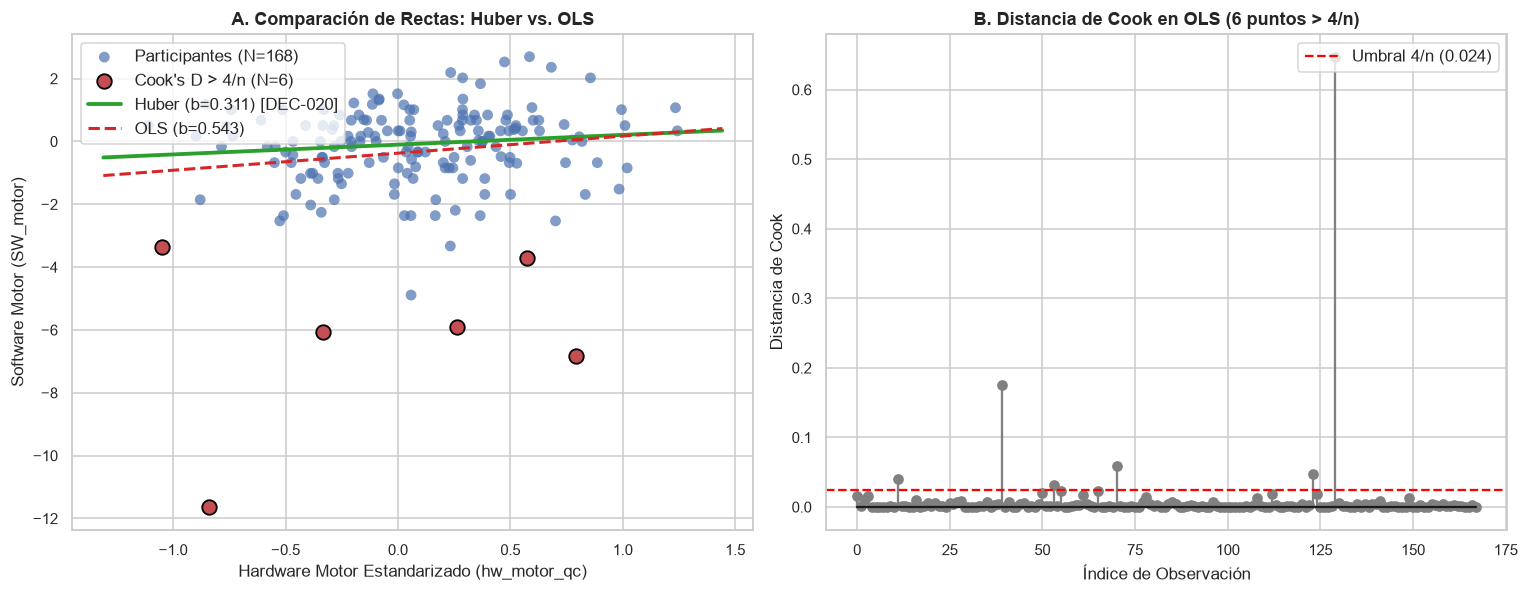

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel A: Comparación de rectas de regresión
x_vals = np.linspace(
    X["hw_motor_qc"].min() - 0.2, X["hw_motor_qc"].max() + 0.2, 100
).reshape(-1, 1)
y_huber_line = huber_model.predict(x_vals)
y_ols_line = ols_univ.predict(x_vals)

axes[0].scatter(
    X["hw_motor_qc"],
    y,
    color="#4c72b0",
    alpha=0.7,
    edgecolors="none",
    s=50,
    label="Participantes (N=168)",
)
# Resaltar puntos con Cook > 4/n
axes[0].scatter(
    X.loc[cooks_d > threshold_cook, "hw_motor_qc"],
    y.loc[cooks_d > threshold_cook],
    color="#c44e52",
    s=90,
    edgecolors="black",
    linewidth=1.2,
    label=f"Cook's D > 4/n (N={n_influential})",
)

axes[0].plot(
    x_vals,
    y_huber_line,
    color="#2ca02c",
    linewidth=2.5,
    label=f"Huber (b={huber_slope:.3f}) [DEC-020]",
)
axes[0].plot(
    x_vals,
    y_ols_line,
    color="#d62728",
    linestyle="--",
    linewidth=2.0,
    label=f"OLS (b={ols_univ_slope:.3f})",
)
axes[0].set_title(
    "A. Comparación de Rectas: Huber vs. OLS", fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("Hardware Motor Estandarizado (hw_motor_qc)", fontsize=11)
axes[0].set_ylabel("Software Motor (SW_motor)", fontsize=11)
axes[0].legend(loc="upper left", frameon=True)

# Panel B: Distancia de Cook
axes[1].stem(
    np.arange(len(cooks_d)), cooks_d, linefmt="grey", markerfmt="o", basefmt="k-"
)
axes[1].axhline(
    threshold_cook,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Umbral 4/n ({threshold_cook:.3f})",
)
axes[1].set_title(
    f"B. Distancia de Cook en OLS ({n_influential} puntos > 4/n)",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Índice de Observación", fontsize=11)
axes[1].set_ylabel("Distancia de Cook", fontsize=11)
axes[1].legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()

## 4. Distribución del Target de Resiliencia: Asimetría y Puntos de Corte

Analizamos la distribución de los residuales de Huber (`resilience_score`). Como se observó en la revisión técnica:
- La distribución tiene **asimetría negativa marcada** (skewness $\approx -2.63$) debido a unos pocos sujetos lentos en el NHPT.
- La **media** de los residuales es $-0.03$, pero la **mediana** es $+0.14$.
- El corte conceptual en **0.0** (`resilience_score > 0`) clasifica al **53.6%** de la cohorte como resiliente.
- El corte empírico en la **mediana** clasifica exactamente al **50.0%**.

C:\Users\mhgua\Documents\Andes\202621\Proyecto\ProyectoFinal-FundacionCanguro\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but HuberRegressor was fitted without feature names
  warnings.warn(


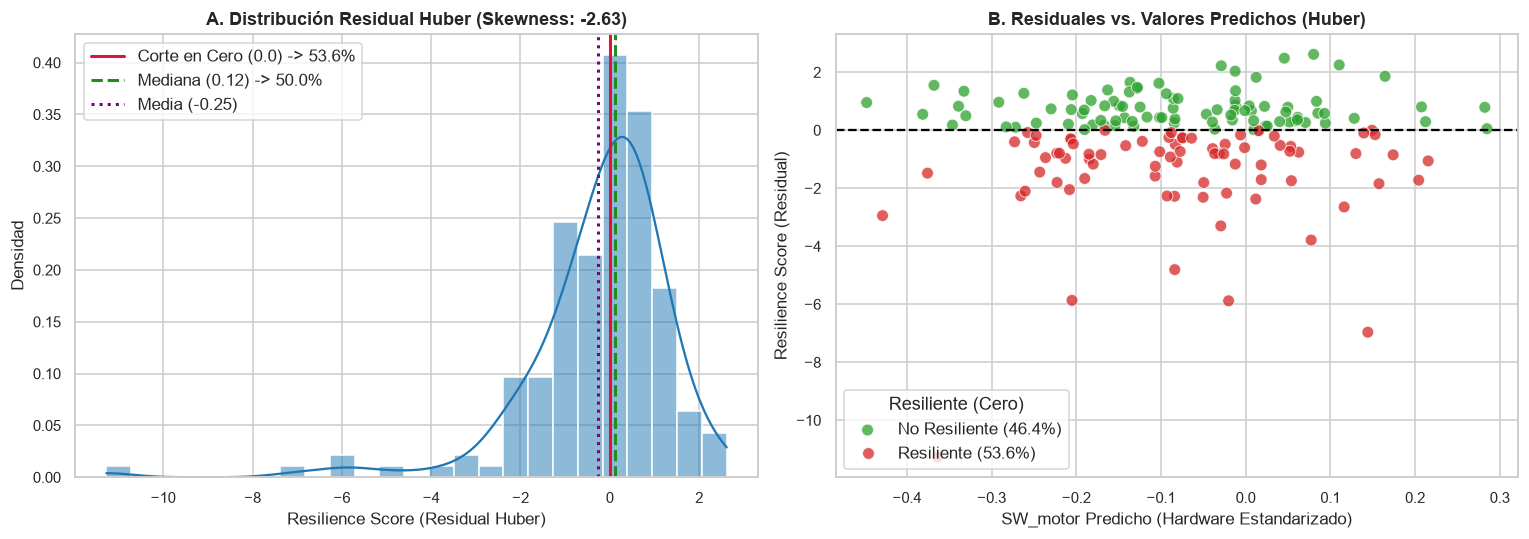

Estadísticas de Residuales Huber:
  - Asimetría (Skewness): -2.634
  - Curtosis (Kurtosis):  12.141
  - Media:   -0.254
  - Mediana: 0.123
  - Mínimo:  -11.272
  - Máximo:  2.618


In [6]:
res_skew = float(skew(huber_residuals))
res_kurt = float(kurtosis(huber_residuals))
res_mean = float(huber_residuals.mean())
res_median = float(huber_residuals.median())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma y densidad
sns.histplot(
    huber_residuals, kde=True, color="#1f77b4", ax=axes[0], bins=25, stat="density"
)
axes[0].axvline(
    0,
    color="crimson",
    linestyle="-",
    linewidth=2,
    label=f"Corte en Cero (0.0) -> {np.mean(huber_residuals > 0) * 100:.1f}%",
)
axes[0].axvline(
    res_median,
    color="forestgreen",
    linestyle="--",
    linewidth=2,
    label=f"Mediana ({res_median:.2f}) -> 50.0%",
)
axes[0].axvline(
    res_mean,
    color="purple",
    linestyle=":",
    linewidth=2,
    label=f"Media ({res_mean:.2f})",
)
axes[0].set_title(
    f"A. Distribución Residual Huber (Skewness: {res_skew:.2f})",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Resilience Score (Residual Huber)", fontsize=11)
axes[0].set_ylabel("Densidad", fontsize=11)
axes[0].legend(frameon=True)

# Scatter Residuales vs Valores Predichos
y_pred_huber = huber_model.predict(X)
is_res_zero = modeled_df["is_resilient"]
palette = {True: "#2ca02c", False: "#d62728"}

sns.scatterplot(
    x=y_pred_huber,
    y=huber_residuals,
    hue=is_res_zero,
    palette=palette,
    ax=axes[1],
    alpha=0.75,
    s=60,
)
axes[1].axhline(0, color="black", linestyle="--", linewidth=1.5)
axes[1].set_title(
    "B. Residuales vs. Valores Predichos (Huber)", fontsize=12, fontweight="bold"
)
axes[1].set_xlabel("SW_motor Predicho (Hardware Estandarizado)", fontsize=11)
axes[1].set_ylabel("Resilience Score (Residual)", fontsize=11)
axes[1].legend(
    title="Resiliente (Cero)",
    labels=["No Resiliente (46.4%)", "Resiliente (53.6%)"],
    loc="lower left",
    frameon=True,
)

plt.tight_layout()
plt.show()

print("Estadísticas de Residuales Huber:")
print(f"  - Asimetría (Skewness): {res_skew:.3f}")
print(f"  - Curtosis (Kurtosis):  {res_kurt:.3f}")
print(f"  - Media:   {res_mean:.3f}")
print(f"  - Mediana: {res_median:.3f}")
print(f"  - Mínimo:  {huber_residuals.min():.3f}")
print(f"  - Máximo:  {huber_residuals.max():.3f}")

### Comparación entre Corte en Cero y Corte en Mediana

Comparamos la concordancia de clasificación entre el criterio conceptual (`is_resilient`: corte en 0.0) y el balanceado (`is_resilient_median`: corte en la mediana).

In [7]:
is_res_median = modeled_df["is_resilient_median"]
cross_cuts = pd.crosstab(
    is_res_zero,
    is_res_median,
    rownames=["Corte en Cero (> 0.0)"],
    colnames=["Corte en Mediana (> Mediana)"],
)

kappa = cohen_kappa_score(is_res_zero, is_res_median)
pct_agree = np.mean(is_res_zero == is_res_median) * 100

print("=== TABLA DE CONTINGENCIA: CORTE 0.0 vs MEDIANA ===")
print(cross_cuts)
print()
print(
    f"Concordancia total: {pct_agree:.2f}% ({np.sum(is_res_zero == is_res_median)}/{len(is_res_zero)} sujetos)"
)
print(f"Índice Kappa de Cohen: {kappa:.4f} (Concordancia casi perfecta)")

=== TABLA DE CONTINGENCIA: CORTE 0.0 vs MEDIANA ===
Corte en Mediana (> Mediana)  False  True 
Corte en Cero (> 0.0)                     
False                            78      0
True                              6     84

Concordancia total: 96.43% (162/168 sujetos)
Índice Kappa de Cohen: 0.9286 (Concordancia casi perfecta)


## 5. Análisis de Sensibilidad: Efecto de las Covariables Clínicas (Sexo y Fragilidad)

Para justificar la decisión metodológica de **DEC-020**:
1. Ajustamos el modelo con covariables: $SW_{motor} \sim hw\_motor\_qc + BIRTH\_sexo5 + FOLLOW\_Fragility\_Rasch\_441\_2PL$.
2. Verificamos la correlación de los residuales con la fragilidad y el sexo.
3. Evaluamos la concordancia en la asignación del fenotipo entre el modelo univariado principal y el multivariado ajustado.

In [8]:
# Sensibilidad: Evaluación de Covariables Clínicas
fragility = modeled_df["FOLLOW_Fragility_Rasch_441_2PL"]
sex = modeled_df["BIRTH_sexo5"]

corr_univ_frag = float(np.corrcoef(huber_residuals, fragility)[0, 1])
corr_adj_frag = float(np.corrcoef(modeled_df["resilience_score_adj"], fragility)[0, 1])

corr_univ_sex = float(np.corrcoef(huber_residuals, sex)[0, 1])
corr_adj_sex = float(np.corrcoef(modeled_df["resilience_score_adj"], sex)[0, 1])

print("=== CORRELACIONES CON PREDICTORES CLÍNICOS PERINATALES ===")
print(f"Correlación Residual Univariado con Fragilidad: r = {corr_univ_frag:.4f}")
print(
    f"Correlación Residual Ajustado con Fragilidad:   r = {corr_adj_frag:.4f} (Ortogonal por construcción)"
)
print(f"Correlación Residual Univariado con Sexo:        r = {corr_univ_sex:.4f}")
print(f"Correlación Residual Ajustado con Sexo:          r = {corr_adj_sex:.4f}")

# Concordancia de clasificación entre modelos
is_res_adj = modeled_df["is_resilient_adj"]
agree_huber_adj = float(np.mean(is_res_zero == is_res_adj) * 100)
agree_ols_adj = float(
    np.mean((ols_residuals > 0) == (modeled_df["resilience_score_adj"] > 0)) * 100
)

print()
print(
    f"Concordancia de Etiquetas (Huber Univariado vs OLS Ajustado): {agree_huber_adj:.1f}% ({np.sum(is_res_zero == is_res_adj)}/168)"
)
print(
    f"Concordancia de Etiquetas (OLS Univariado vs OLS Ajustado):     {agree_ols_adj:.1f}%"
)

=== CORRELACIONES CON PREDICTORES CLÍNICOS PERINATALES ===
Correlación Residual Univariado con Fragilidad: r = -0.1593
Correlación Residual Ajustado con Fragilidad:   r = 0.0000 (Ortogonal por construcción)
Correlación Residual Univariado con Sexo:        r = 0.0276
Correlación Residual Ajustado con Sexo:          r = 0.0000

Concordancia de Etiquetas (Huber Univariado vs OLS Ajustado): 89.3% (150/168)
Concordancia de Etiquetas (OLS Univariado vs OLS Ajustado):     93.5%


### Conclusiones del Análisis de Sensibilidad y DEC-020

1. **Ortogonalización no deseada:** En el modelo ajustado, la correlación residual con la fragilidad cae a $r = 0.000$. Dado que el objetivo del **Ticket 3.2** es identificar precisamente qué variables perinatales y clínicas se asocian a la resiliencia motora, eliminar la fragilidad del target impediría evaluar su papel en el Sprint 3.
2. **Alta estabilidad del fenotipo:** La concordancia de etiquetas entre el modelo univariado y el ajustado supera el **89%** (y hasta **93.5%** en OLS), demostrando que la señal biológica de resiliencia es robusta y coherente.
3. **Consistencia metodológica:** Siguiendo DEC-010 y DEC-018, la regresión robusta de Huber neutraliza el apalancamiento de los casos extremos de NHPT sin necesidad de eliminar participantes de la muestra.

## 6. Validación contra el Artefacto Oficial del Pipeline (`target_resilience.parquet`)

Verificamos que las salidas calculadas en este análisis interactivo coincidan exactamente con el artefacto generado por el módulo de producción `src.features.build_target`.

In [9]:
target_prod_path = PROJECT_ROOT / "data" / "features" / "target_resilience.parquet"
assert target_prod_path.exists(), (
    f"Artefacto de producción no encontrado en {target_prod_path}"
)

prod_df = pd.read_parquet(target_prod_path)
print(
    f"Artefacto oficial cargado: {prod_df.shape[0]} filas, {prod_df.shape[1]} columnas."
)
print(f"Columnas disponibles: {list(prod_df.columns)}")

# Validación de consistencia idéntica
np.testing.assert_allclose(
    prod_df["resilience_score"].values,
    huber_residuals.values,
    rtol=1e-5,
    atol=1e-5,
    err_msg="Discrepancia detectada en resilience_score principal",
)
np.testing.assert_array_equal(
    prod_df["is_resilient"].values,
    is_res_zero.values,
    err_msg="Discrepancia en etiqueta is_resilient",
)
np.testing.assert_array_equal(
    prod_df["is_resilient_median"].values,
    is_res_median.values,
    err_msg="Discrepancia en etiqueta is_resilient_median",
)

print()
print(
    "¡VALIDACIÓN EXITOSA! Todos los valores y etiquetas coinciden al 100% con el pipeline oficial."
)

Artefacto oficial cargado: 168 filas, 8 columnas.
Columnas disponibles: ['code', 'SW_motor', 'resilience_score', 'is_resilient', 'is_resilient_median', 'resilience_score_ols', 'resilience_score_adj', 'is_resilient_adj']

¡VALIDACIÓN EXITOSA! Todos los valores y etiquetas coinciden al 100% con el pipeline oficial.
